# RGB-to-Grayscale Image Conversion Algorithms

Converting an RGB image to grayscale consists of calculating a single intensity value for each pixel based on its red (R), green (G), and blue (B) components. Different algorithms can be used to perform this conversion. This study evaluates three methods:

### 1. Simple Average

This method calculates the arithmetic mean of the three color channels:

$$
Grayscale = \frac{R+G+B}{3}
$$

It is a straightforward approach; however, it does not account for the different contributions of each color channel to perceived brightness.

### 2. Luma Method (Weighted RGB)

This method assigns different weights to the RGB channels according to their contribution to perceived brightness:
$$
Grayscale = 0.299R+0.587G+0.114B
$$

The green channel has the greatest weight, followed by red and blue.

### 3. Desaturation Method (Minimum and Maximum)

This method calculates the average between the maximum and minimum values of the three color channels:
$$
Grayscale = \frac{\max(R,G,B)+\min(R,G,B)}{2}
$$

It provides an alternative approach to grayscale conversion based on the range of RGB channel intensities.

## Experimental Reproducibility

### Instructions for running the experiment

1. Open this notebook in Google Colab.
2. Download the ten original RGB images from the `data` folder of this repository.
3. Run the image upload cell and select the ten JPEG files.
4. Execute the notebook cells sequentially.
5. The images will be resized to 1920 × 1080 pixels before processing.
6. The experiment will evaluate three grayscale conversion algorithms using 50 repetitions per image and method.
7. The resulting CSV files will be generated automatically in the execution environment.

**Note:** The original experimental measurements are provided in the `results` folder. Running the experiment again will generate new measurements, which may differ slightly depending on the computational environment.

In [ ]:
from google.colab import files

print("Select the 10 original RGB images:")
archivos = files.upload()

if len(archivos) != 10:
    raise ValueError("Please upload exactly 10 images.")

print(f"\nSuccessfully uploaded {len(archivos)} images.")

Select the 10 original RGB images:


Saving image (1).jpg to image (1).jpg
Saving image (2).jpg to image (2).jpg
Saving image (3).jpg to image (3).jpg
Saving image (4).jpg to image (4).jpg
Saving image (5).jpg to image (5).jpg
Saving image (6).jpg to image (6).jpg
Saving image (7).jpg to image (7).jpg
Saving image (8).jpg to image (8).jpg
Saving image (9).jpg to image (9).jpg
Saving image (10).jpg to image (10).jpg

Successfully uploaded 10 images.


# Experimental Implementation and Performance Evaluation

In [ ]:

# ============================================================
# EXPERIMENTO: COMPARACIÓN DE TRES MÉTODOS RGB A ESCALA DE GRISES
# Plataforma: Google Colab
#
# Métodos:
# 1. Promedio simple
# 2. Modelo Luma
# 3. Desaturación
#
# Se comparan:
# - Tiempo de ejecución
# - Características visuales de las imágenes obtenidas
# ============================================================

import cv2
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

from google.colab import files
from io import BytesIO
from PIL import Image

# ------------------------------------------------------------
# 1. CONFIGURACIÓN DEL EXPERIMENTO
# ------------------------------------------------------------

REPETICIONES = 50

# Tamaño común para todas las imágenes.
# Se usa el mismo tamaño para que la comparación sea más justa.
ANCHO = 1920
ALTO = 1080

print("Experimento de conversión RGB a escala de grises")
print(f"Repeticiones por método e imagen: {REPETICIONES}")
print(f"Resolución de prueba: {ANCHO} x {ALTO} píxeles")


# ------------------------------------------------------------
# 2. CARGAR LAS IMÁGENES
# ------------------------------------------------------------

imagenes = {}

for nombre, contenido in archivos.items():

    # Abrir imagen y convertirla a RGB
    imagen = Image.open(BytesIO(contenido)).convert("RGB")
    imagen = np.array(imagen)

    # Redimensionar todas las imágenes a la misma resolución
    imagen = cv2.resize(
        imagen,
        (ANCHO, ALTO),
        interpolation=cv2.INTER_AREA
    )

    imagenes[nombre] = imagen

print(f"\nTotal de imágenes cargadas: {len(imagenes)}")


# ------------------------------------------------------------
# 3. MÉTODO 1: PROMEDIO SIMPLE
# ------------------------------------------------------------

def promedio_simple(imagen):
    R = imagen[:, :, 0].astype(np.float32)
    G = imagen[:, :, 1].astype(np.float32)
    B = imagen[:, :, 2].astype(np.float32)

    gris = (R + G + B) / 3.0

    return np.rint(gris).astype(np.uint8)


# ------------------------------------------------------------
# 4. MÉTODO 2: MODELO LUMA
# ------------------------------------------------------------

def modelo_luma(imagen):
    R = imagen[:, :, 0].astype(np.float32)
    G = imagen[:, :, 1].astype(np.float32)
    B = imagen[:, :, 2].astype(np.float32)

    gris = 0.299 * R + 0.587 * G + 0.114 * B

    return np.rint(gris).astype(np.uint8)


# ------------------------------------------------------------
# 5. MÉTODO 3: DESATURACIÓN
# ------------------------------------------------------------

def desaturacion(imagen):
    maximo = np.max(imagen, axis=2).astype(np.uint16)
    minimo = np.min(imagen, axis=2).astype(np.uint16)

    gris = (maximo + minimo) / 2.0

    return np.rint(gris).astype(np.uint8)


# Diccionario de métodos
metodos = {
    "Promedio simple": promedio_simple,
    "Modelo Luma": modelo_luma,
    "Desaturación": desaturacion
}


# ------------------------------------------------------------
# 6. MEDICIÓN DEL TIEMPO DE EJECUCIÓN
# ------------------------------------------------------------

resultados = []
salidas = {}

for nombre_imagen, imagen in imagenes.items():

    print(f"\nProcesando imagen: {nombre_imagen}")

    salidas[nombre_imagen] = {}

    for nombre_metodo, funcion in metodos.items():

        # Ejecución de calentamiento: no se incluye en las mediciones
        funcion(imagen)

        tiempos = []

        for _ in range(REPETICIONES):

            inicio = time.perf_counter_ns()
            resultado = funcion(imagen)
            fin = time.perf_counter_ns()

            tiempo_ms = (fin - inicio) / 1_000_000
            tiempos.append(tiempo_ms)

        # Guardar una imagen resultante para comparación visual
        salidas[nombre_imagen][nombre_metodo] = resultado

        resultados.append({
            "Imagen": nombre_imagen,
            "Método": nombre_metodo,
            "Tiempo promedio (ms)": np.mean(tiempos),
            "Desviación estándar (ms)": np.std(tiempos, ddof=1),
            "Repeticiones": REPETICIONES
        })

        print(
            f"  {nombre_metodo}: "
            f"{np.mean(tiempos):.4f} ms "
            f"± {np.std(tiempos, ddof=1):.4f} ms"
        )


# ------------------------------------------------------------
# 7. TABLA DE RESULTADOS POR IMAGEN
# ------------------------------------------------------------

df = pd.DataFrame(resultados)

print("\nRESULTADOS POR IMAGEN")
display(df.round(4))


# ------------------------------------------------------------
# 8. RESUMEN GENERAL DE LOS MÉTODOS
# ------------------------------------------------------------

resumen = (
    df.groupby("Método", sort=False)
      .agg(
          Tiempo_promedio_ms=("Tiempo promedio (ms)", "mean"),
          Desviacion_entre_imagenes_ms=(
              "Tiempo promedio (ms)", "std"
          )
      )
      .reset_index()
)

print("\nRESUMEN GENERAL")
display(resumen.round(4))


# ------------------------------------------------------------
# 9. GRÁFICA COMPARATIVA DE TIEMPOS
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

plt.bar(
    resumen["Método"],
    resumen["Tiempo_promedio_ms"]
)

plt.ylabel("Tiempo promedio de ejecución (ms)")
plt.xlabel("Método de conversión")
plt.title("Comparación del tiempo de ejecución")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 10. COMPARACIÓN VISUAL DE LAS IMÁGENES
# ------------------------------------------------------------

# Se muestra cada imagen original junto a sus tres conversiones.

for nombre_imagen, imagen in imagenes.items():

    fig, ejes = plt.subplots(1, 4, figsize=(16, 5))

    ejes[0].imshow(imagen)
    ejes[0].set_title("Imagen original")

    for eje, nombre_metodo in zip(
        ejes[1:],
        metodos.keys()
    ):
        eje.imshow(
            salidas[nombre_imagen][nombre_metodo],
            cmap="gray",
            vmin=0,
            vmax=255
        )
        eje.set_title(nombre_metodo)

    for eje in ejes:
        eje.axis("off")

    fig.suptitle(
        f"Comparación visual: {nombre_imagen}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()


# ------------------------------------------------------------
# 11. EXPORTAR LOS RESULTADOS
# ------------------------------------------------------------

df.to_csv(
    "resultados_por_imagen.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen.to_csv(
    "resumen_general.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nArchivos CSV generados.")

files.download("resultados_por_imagen.csv")
files.download("resumen_general.csv")


Output hidden; open in https://colab.research.google.com to view.

**GRAFICANDO**

Upload the original resumen_general.csv file:


Saving resumen_general.csv to resumen_general (5).csv
Selected file: resumen_general (5).csv
CSV loaded and validated successfully.


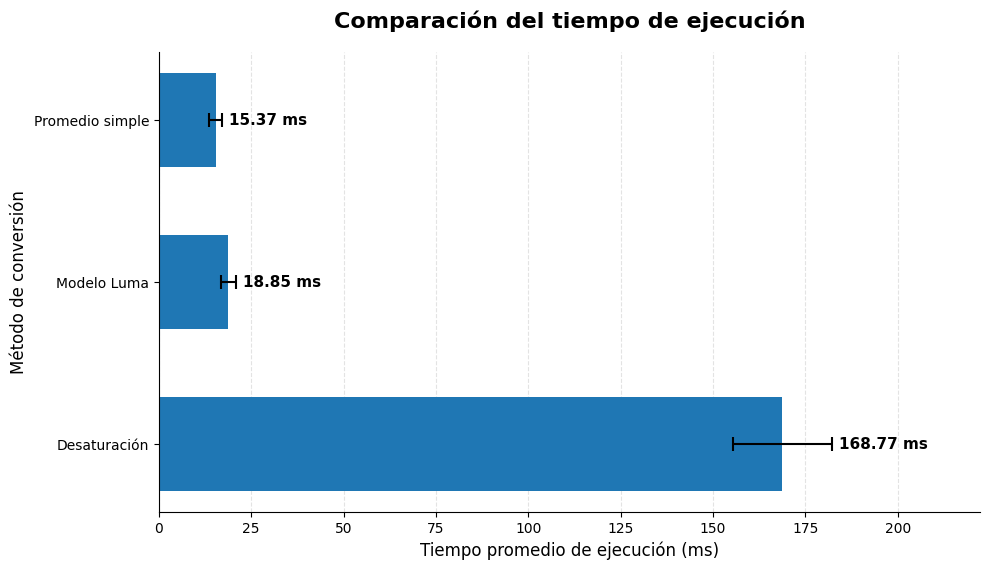

Graph saved as: Figura_3_tiempo_ejecucion.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from google.colab import files
from io import BytesIO

# ============================================================
# FIGURA 3. COMPARACIÓN DEL TIEMPO DE EJECUCIÓN
# DE LOS MÉTODOS DE CONVERSIÓN RGB A ESCALA DE GRISES
# ============================================================

# ------------------------------------------------------------
# 1. CARGAR EL ARCHIVO CSV ORIGINAL
# ------------------------------------------------------------

print("Upload the original resumen_general.csv file:")

archivos_csv = files.upload()

if not archivos_csv:
    raise ValueError("No CSV file was uploaded.")

# Obtener el nombre del archivo seleccionado.
# Esto permite aceptar nombres modificados automáticamente
# por Google Colab, por ejemplo: resumen_general (4).csv.

nombre_archivo = next(iter(archivos_csv))

if not nombre_archivo.lower().endswith(".csv"):
    raise ValueError("Please upload a CSV file.")

print(f"Selected file: {nombre_archivo}")

datos = pd.read_csv(
    BytesIO(archivos_csv[nombre_archivo])
)

# ------------------------------------------------------------
# 2. VALIDAR LA ESTRUCTURA DEL ARCHIVO
# ------------------------------------------------------------

columnas_requeridas = [
    "Método",
    "Tiempo_promedio_ms",
    "Desviacion_entre_imagenes_ms"
]

if not all(col in datos.columns for col in columnas_requeridas):
    raise ValueError(
        "The CSV does not contain the required columns."
    )

if len(datos) != 3:
    raise ValueError(
        "The CSV must contain exactly three methods."
    )

if datos[columnas_requeridas].isnull().any().any():
    raise ValueError(
        "The CSV contains missing values."
    )

print("CSV loaded and validated successfully.")

# ------------------------------------------------------------
# 3. EXTRAER LOS DATOS
# ------------------------------------------------------------

metodos = datos["Método"].astype(str).to_numpy()

tiempos = pd.to_numeric(
    datos["Tiempo_promedio_ms"]
).to_numpy()

desviacion = pd.to_numeric(
    datos["Desviacion_entre_imagenes_ms"]
).to_numpy()

if not (
    np.isfinite(tiempos).all()
    and np.isfinite(desviacion).all()
):
    raise ValueError("The CSV contains invalid numerical values.")

if (tiempos < 0).any() or (desviacion < 0).any():
    raise ValueError("Times and standard deviations must be non-negative.")

# ------------------------------------------------------------
# 4. ORDENAR LOS MÉTODOS
# ------------------------------------------------------------

# Ordenar para mostrar el método más rápido arriba.

orden = np.argsort(tiempos)[::-1]

metodos = metodos[orden]
tiempos = tiempos[orden]
desviacion = desviacion[orden]

# ------------------------------------------------------------
# 5. CREAR LA FIGURA
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5.8))

barras = ax.barh(
    metodos,
    tiempos,
    xerr=desviacion,
    height=0.58,
    capsize=5,
    error_kw={
        "elinewidth": 1.5,
        "capthick": 1.5
    }
)

# ------------------------------------------------------------
# 6. AGREGAR ETIQUETAS NUMÉRICAS
# ------------------------------------------------------------

for barra, valor, error in zip(
    barras,
    tiempos,
    desviacion
):
    ax.text(
        valor + error + 2,
        barra.get_y() + barra.get_height() / 2,
        f"{valor:.2f} ms",
        va="center",
        ha="left",
        fontsize=11,
        fontweight="bold"
    )

# ------------------------------------------------------------
# 7. FORMATO DE LA GRÁFICA
# ------------------------------------------------------------

ax.set_title(
    "Comparación del tiempo de ejecución",
    fontsize=16,
    fontweight="bold",
    pad=18
)

ax.set_xlabel(
    "Tiempo promedio de ejecución (ms)",
    fontsize=12
)

ax.set_ylabel(
    "Método de conversión",
    fontsize=12
)

ax.grid(
    axis="x",
    linestyle="--",
    alpha=0.35
)

ax.set_axisbelow(True)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# Espacio para etiquetas y barras de error.

limite = max(tiempos + desviacion)
ax.set_xlim(0, limite * 1.22)

plt.tight_layout()

# ------------------------------------------------------------
# 8. GUARDAR LA FIGURA EN ALTA RESOLUCIÓN
# ------------------------------------------------------------

nombre_salida = "Figura_3_tiempo_ejecucion.png"

plt.savefig(
    nombre_salida,
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# ------------------------------------------------------------
# 9. MOSTRAR Y DESCARGAR EL ARCHIVO
# ------------------------------------------------------------

print(f"Graph saved as: {nombre_salida}")

files.download(nombre_salida)


# IDENTIFICANDO EL ENTORNO COMPUTACIONAL

In [ ]:

# ============================================================
# INFORMACIÓN DEL ENTORNO COMPUTACIONAL
# Artículo: Conversión de imágenes RGB a escala de grises
# Propósito: Identificar versiones de software y hardware.
# Esta celda no modifica ni repite los experimentos originales.
# ============================================================

import sys
import platform
import numpy as np
import cv2
import os

print("===== INFORMACIÓN DEL ENTORNO =====")

print("\n--- SOFTWARE ---")
print("Versión de Python:", sys.version)
print("Versión de NumPy:", np.__version__)
print("Versión de OpenCV:", cv2.__version__)

print("\n--- SISTEMA ---")
print("Sistema operativo:", platform.platform())
print("Arquitectura:", platform.architecture()[0])
print("Procesador:", platform.processor())

print("\n--- CPU DISPONIBLE ---")
print("Número de CPU lógicas:", os.cpu_count())

print("\n--- VARIABLES DEL ENTORNO ---")
for variable in ["COLAB_RELEASE_TAG", "COLAB_GPU"]:
    print(variable + ":", os.environ.get(variable, "No disponible"))


===== INFORMACIÓN DEL ENTORNO =====

--- SOFTWARE ---
Versión de Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Versión de NumPy: 2.4.6
Versión de OpenCV: 5.0.0

--- SISTEMA ---
Sistema operativo: Linux-6.6.159+-x86_64-with-glibc2.39
Arquitectura: 64bit
Procesador: x86_64

--- CPU DISPONIBLE ---
Número de CPU lógicas: 2

--- VARIABLES DEL ENTORNO ---
COLAB_RELEASE_TAG: release-colab-external-images_20261109-060054_RC00
COLAB_GPU: 
